In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


## Adding W&B API key

In [2]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
WB_KEY = user_secrets.get_secret("WANDB_API_KEY")


In [3]:
import wandb

wandb.login(key=WB_KEY)

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


True

In [4]:
!pip install -q chonkie sentence-transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.9/230.9 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 387.2/387.2 kB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 68.1 MB/s eta 0:00:00


In [5]:
import wandb

print("Initializing wandb")

run = wandb.init(
    entity="ambatwar-iitm",
    project="dlgenai-t226",
    name="mcq-solver-full-pipeline",
    config={
        "task": "smart-mcq-solver-challenge",
    },
)

print("W&B run:", run.url)

Initializing wandb


wandb: setting up run uhuagkwc
wandb: Tracking run with wandb version 0.25.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260706_220730-uhuagkwc
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run mcq-solver-full-pipeline
wandb: ⭐️ View project at https://wandb.ai/ambatwar-iitm/dlgenai-t226
wandb: 🚀 View run at https://wandb.ai/ambatwar-iitm/dlgenai-t226/runs/uhuagkwc


W&B run: https://wandb.ai/ambatwar-iitm/dlgenai-t226/runs/uhuagkwc


## Step 1 - Setup & environment check

In [6]:
import sys, platform
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import transformers

import matplotlib.pyplot as plt

print("Python      :", sys.version.split()[0])
print("Platform    :", platform.system(), platform.release())
print("NumPy       :", np.__version__)
print("Pandas      :", pd.__version__)
print("PyTorch     :", torch.__version__)
print("Transformers:", transformers.__version__)
print("-" * 45)

# The device we'll use for all tensor computation.
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device      :", device)
if device == "cuda":
    print("GPU         :", torch.cuda.get_device_name(0))
    print("VRAM (GB)   :", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
print("-" * 45)

# Confirm the dataset files exist (paths are relative to this notebook's folder).
DATA_DIR = Path("/kaggle/input/competitions/smart-mcq-solver-challenge")
for fname in ["train.csv", "test.csv", "sample_submission.csv"]:
    fpath = DATA_DIR / fname
    status = "FOUND   " if fpath.exists() else "MISSING!"
    print(f"{fname:22s} {status} -> {fpath}")

#import os
#from kaggle_secrets import UserSecretsClient
#os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")

Python      : 3.12.13
Platform    : Linux 6.12.90+
NumPy       : 2.4.6
Pandas      : 2.3.3
PyTorch     : 2.10.0+cpu
Transformers: 5.0.0
---------------------------------------------
Device      : cpu
---------------------------------------------
train.csv              FOUND    -> /kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
test.csv               FOUND    -> /kaggle/input/competitions/smart-mcq-solver-challenge/test.csv
sample_submission.csv  FOUND    -> /kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv


## Step 2 - Reading input

In [7]:
train = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")
test = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")
sample_sub = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv")

train.head()

,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


In [8]:
test.head()


,id,prompt,A,B,C,D,E
0,1,Pick the best possible answer: What is the rel...,"For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p..."
1,2,"What is the estimated redshift of CEERS-93316,...","Approximately z = 6.0, corresponding to 1 bill...","Approximately z = 16.7, corresponding to 235.8...","Approximately z = 3.0, corresponding to 5 bill...","Approximately z = 10.0, corresponding to 13 bi...","Approximately z = 13.0, corresponding to 30 bi..."
2,3,Pick the best possible answer: What is the rea...,The sun appears yellowish due to a reflection ...,"The longer wavelengths of light, such as red a...",The sun appears yellowish due to the scatterin...,The sun emits a yellow light due to its own sp...,The atmosphere absorbs the shorter wavelengths...
3,4,What is the significance of the redshift-dista...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...
4,5,What is the Landau-Lifshitz-Gilbert equation u...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...


In [9]:
train.describe()

,id
count,2000.000000
mean,1000.500000
std,577.494589
min,1.000000
25%,500.750000
50%,1000.500000
75%,1500.250000
max,2000.000000


In [10]:
# check the shape of train and test
print(train.shape)
print(test.shape)
print(sample_sub.shape)

(2000, 8)
(500, 7)
(500, 2)


In [11]:
print("train columns:", list(train.columns))
print("test columns :", list(test.columns))
print()

print("Missing values per column (train):")
print(train.isna().sum().to_string())
print()

train columns: ['id', 'prompt', 'A', 'B', 'C', 'D', 'E', 'answer']
test columns : ['id', 'prompt', 'A', 'B', 'C', 'D', 'E']

Missing values per column (train):
id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0



In [12]:
def show_question(row, show_answer=True):
    """ Preety-print a single question row so it is easy to read. """
    print("PROMPT:")
    print("  " + str(row["prompt"]))
    print()
    for opt in ["A", "B", "C", "D", "E"]:
        print(f"  {opt}) {row[opt]}")
    if show_answer and "answer" in row.index:
        print()
        print(" CORRECT ANSWER:", row["answer"])

print("=" * 80)
print("ONE EXAMPLE FROM THE TRAINING SET")
print("=" * 80)
show_question(train.iloc[0])
print("=" *80)

ONE EXAMPLE FROM THE TRAINING SET
PROMPT:
  Pick the best possible answer: What is Martin Heidegger's view on the relationship between time and human existence? among the listed options.

  A) Martin Heidegger believes that humans exist within a time continuum that is infinite and does not have a defined beginning or end. The relationship to the past involves acknowledging it as a historical era, and the relationship to the future involves creating a world that will endure beyond one's own time.
  B) Martin Heidegger believes that humans do not exist inside time, but that they are time. The relationship to the past is a present awareness of having been, and the relationship to the future involves anticipating a potential possibility, task, or engagement.
  C) Martin Heidegger does not believe in the existence of time or that it has any effect on human consciousness. The relationship to the past and the future is insignificant, and human existence is solely based on the present.
  D) Ma

## Step 3 - Explore the data (EDA)

EDA stands for Exploratory Data Analysis. Before any modeling we ask simple questions about the data, because the answers change every later decision:

1. **How are the correct answers distributed across A, B, C, D, E?**
   - If they are roughly equal, there is no shortcut: a constant guess like "A B C" cannot beat chance.
   - If one letter is much more common, even a simple baseline can exploit that bias.
2. **How long are the prompts and options (in words)?**
   - This sets the maximum sequence length we feed a transformer later, which directly drives GPU memory use - critical on our 4 GB card.

Run the cell below.

In [13]:
train["answer"]

0       B
1       A
2       C
3       B
4       A
       ..
1995    B
1996    E
1997    D
1998    B
1999    C
Name: answer, Length: 2000, dtype: object

Correct answer distribution in train (out of 2000):
 A:  369 (18.4%)
 B:  490 (24.5%)
 C:  459 (23.0%)
 D:  358 (17.9%)
 E:  324 (16.2%)

Prompt length in words:
count    2000.0
mean       18.1
std         6.8
min         3.0
25%        14.0
50%        17.0
75%        22.0
max        51.0

Longest option length in words (per question):
count    2000.0
mean       30.5
std        19.0
min         1.0
25%        17.0
50%        28.0
75%        42.0
max       118.0


Text(0.5, 0, 'words per prompt')

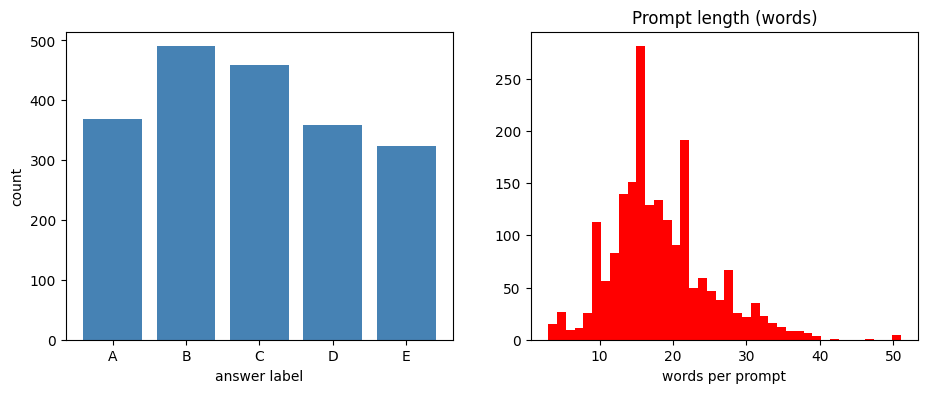

In [14]:
# === Step 3: Explore the data (EDA) ===
import matplotlib.pyplot as plt

option_cols = ["A", "B", "C", "D", "E"]

# --- 1) Distribution of the correct answer label ---
answer_counts = train["answer"].value_counts().reindex(option_cols).fillna(0).astype(int)
answer_percent = (train["answer"].value_counts(normalize=True).reindex(option_cols).fillna(0) * 100).round(1)
print("Correct answer distribution in train (out of 2000):")
for label in option_cols:
    print(f" {label}: {answer_counts[label]:4d} ({answer_percent[label]}%)")
print()

# --- 2) Text length analysis (counted in words) ---
train["prompt_words"] = train["prompt"].str.split().str.len()
train["max_option_words"] = train[option_cols].apply(
    lambda r: max(len(str(x).split()) for x in r), axis=1
)

print("Prompt length in words:")
print(train["prompt_words"].describe().round(1).to_string())
print()
print("Longest option length in words (per question):")
print(train["max_option_words"].describe().round(1).to_string())

# --- 3) Visualize ---
figure, axes = plt.subplots(1, 2, figsize = (11, 4))
axes[0].bar(answer_counts.index, answer_counts.values, color="steelblue")
axes[0].set_xlabel("answer label")
axes[0].set_ylabel("count")

axes[1].hist(train["prompt_words"], bins=40, color="red")
axes[1].set_title("Prompt length (words)")
axes[1].set_xlabel("words per prompt")


It's mildly imbalanced. B and C come up more often; E least. The data isn't perfectly flat, so the smartest constant guess is the three most frequent letters in order: "B C A", not "A B C". That's a small but free edge we'll measure in a moment. The key lesson: a model still has to actually read the question - you can't win on label bias alone here.

Prompt length (right chart): most prompts are 10-30 words (peak ~15), tailing off by ~50. Prompts are short. The options, though, are the long part (remember the Heidegger options were ~40-60 words each). So one (prompt + option) pair is roughly 60-90 words ≈ ~150 tokens. That comfortably fits a 256-token limit later - good news for your 4 GB GPU.

Jot those two takeaways in Observations (Step 3) (imbalance toward B/C; prompts short, options longer).

## Step 4 - Build a local scoreboard (metric + validation split + baselines)

We cannot see the test answers, so we need our own honest way to measure progress. Three pieces:

1. **The MAP@3 metric, written by hand.** With one correct answer per question it is simply `1 / (rank of the correct label)` if that label lands in our top 3, otherwise 0. We verify it against the exact example from the problem statement.
2. **A validation set.** We hold out 20% of the training data (stratified, so the A-E balance is preserved). We build and tune on the other 80%, then score ourselves on this untouched 20%. This is how we estimate our leaderboard score before ever submitting.
3. **Two constant baselines** - always guess "A B C", and always guess the three most frequent answers. A baseline is the bar every fancier model must clear to be worth its complexity.

Important idea - **data leakage**: we compute the "most frequent" order from the *training split only*, never from validation. Using the validation data to make our predictions would flatter the score dishonestly.

Run the cell below.

In [15]:
# === Step 4: Local scoreboard - MAP@3 metric, validation split, constant baselines ===
from sklearn.model_selection import train_test_split


# 1) Write the MAP@3 metric ourselves (exactly one correct label per question).
def average_precision_at_3(true_label, predicted_labels):
    """Score one question: 1.0 if correct is 1st, 0.5 if 2nd, 1/3 if 3rd, else 0.0."""
    for rank, label in enumerate(predicted_labels[:3], start=1):
        if label == true_label:
            return 1.0 / rank
    return 0.0


def map_at_3(true_labels, predicted_lists):
    """Mean of the per-question scores over the whole set."""
    scores = [average_precision_at_3(t, p) for t, p in zip(true_labels, predicted_lists)]
    return sum(scores) / len(scores)


# Sanity check against the example in the problem statement (correct answer = A):
assert average_precision_at_3("A", ["A", "B", "C"]) == 1.0
assert average_precision_at_3("A", ["B", "A", "C"]) == 0.5
assert abs(average_precision_at_3("A", ["C", "D", "A"]) - 1 / 3) < 1e-9
assert average_precision_at_3("A", ["C", "D", "E"]) == 0.0
print("MAP@3 metric passes the sanity checks.\n")

# 2) Hold out 20% of train as a validation set (stratified to preserve answer balance).
train_split, valid_split = train_test_split(
    train, test_size=0.2, random_state=42, stratify=train["answer"]
)
valid_true = valid_split["answer"].tolist()
print(f"train_split: {len(train_split)} rows   valid_split: {len(valid_split)} rows\n")

# 3) Constant baselines. The 'frequency' order is learned ONLY from train_split (no leakage).
freq_order = train_split["answer"].value_counts().index.tolist()[:3]
print("Three most frequent answers in train_split:", freq_order, "\n")

baselines = {
    "constant 'A B C'": ["A", "B", "C"],
    f"constant '{' '.join(freq_order)}' (most frequent)": freq_order,
}

scoreboard = {}
for name, guess in baselines.items():
    preds = [guess] * len(valid_split)          # same guess for every validation question
    scoreboard[name] = map_at_3(valid_true, preds)

print("Local validation MAP@3 (higher is better):")
for name, score in sorted(scoreboard.items(), key=lambda kv: kv[1], reverse=True):
    print(f"  {score:.4f}   {name}")

wandb.log(scoreboard)

MAP@3 metric passes the sanity checks.

train_split: 1600 rows   valid_split: 400 rows

Three most frequent answers in train_split: ['B', 'C', 'A'] 

Local validation MAP@3 (higher is better):
  0.4217   constant 'B C A' (most frequent)
  0.3842   constant 'A B C'


## Step 5 - First real model: a TF-IDF word-overlap ranker

This is our first method that actually looks at the question text. The idea in three parts:

1. **Turn text into numbers (TF-IDF vectors).** Each sentence becomes a vector counting which words it contains. Common words like "the" count for little; rarer, more informative words count for more. (TF = term frequency, IDF = inverse document frequency.)
2. **Score each option** by the cosine similarity between its vector and the prompt's vector - i.e. how much vocabulary they share.
3. **Rank the 5 options** by that score and keep the top 3.

We fit the vectorizer on the training split only (no leakage), then score on validation and add the result to our scoreboard.

**What to expect:** probably close to the 0.42 baseline, not far above it. The distractor options reuse the same words as the correct one, so word overlap struggles to separate them. That limitation is exactly what pushes us toward meaning-based models next.

Run the cell below.

In [16]:
# === Step 5: TF-IDF word-overlap ranker ===
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

option_cols = ["A", "B", "C", "D", "E"]

# 1) Fit the vectorizer on the TRAIN SPLIT text only (prompts + options) -> no leakage.
corpus = train_split["prompt"].astype(str).tolist()
for c in option_cols:
    corpus += train_split[c].astype(str).tolist()

vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2)
vectorizer.fit(corpus)
print("Vocabulary size:", len(vectorizer.vocabulary_))


# 2) For a dataframe, rank the 5 options of each row by similarity to its prompt.
def tfidf_rank(df):
    prompt_vecs = vectorizer.transform(df["prompt"].astype(str))          # (n, vocab)
    option_vecs = {c: vectorizer.transform(df[c].astype(str)) for c in option_cols}
    preds = []
    for i in range(len(df)):
        sims = [(c, cosine_similarity(prompt_vecs[i], option_vecs[c][i])[0, 0]) for c in option_cols]
        sims.sort(key=lambda x: x[1], reverse=True)      # highest similarity first
        preds.append([c for c, _ in sims[:3]])           # keep top 3 labels
    return preds


# 3) Evaluate on validation and update the scoreboard.
valid_preds_tfidf = tfidf_rank(valid_split)
scoreboard["TF-IDF word overlap"] = map_at_3(valid_true, valid_preds_tfidf)

print(f"\nTF-IDF word-overlap MAP@3 on validation: {scoreboard['TF-IDF word overlap']:.4f}\n")
print("Scoreboard so far:")
for name, score in sorted(scoreboard.items(), key=lambda kv: kv[1], reverse=True):
    print(f"  {score:.4f}   {name}")

wandb.log({"TF-IDF word overlap": scoreboard["TF-IDF word overlap"]})


Vocabulary size: 10275

TF-IDF word-overlap MAP@3 on validation: 0.3100

Scoreboard so far:
  0.4217   constant 'B C A' (most frequent)
  0.3842   constant 'A B C'
  0.3100   TF-IDF word overlap


## Step 6 - Meaning-based ranking with sentence embeddings (first deep learning)

TF-IDF only counted shared words. Now we use a pretrained transformer - a small, fast one called **MiniLM** - that maps any sentence to a vector capturing its **meaning**, learned from huge amounts of text. Sentences with similar meaning land close together even when they use different words.

Plan:
1. Load the pretrained model (downloads about 80 MB the first time, then it is cached).
2. Encode the prompt and each option into 384-dimensional vectors on the GPU.
3. Rank the options by cosine similarity to the prompt and keep the top 3.

This is the same shape as TF-IDF (vectors -> cosine -> rank), but the vectors now come from a deep neural network instead of word counts.

**Honest expectation:** meaning-similarity is still an imperfect signal here, because every distractor is on-topic and close in meaning to the correct answer. So the gain over the 0.42 baseline may be small - and that is fine. The real jump comes in the next step, when we *train* a model specifically to pick the correct option.

Run the cell below (first run downloads the model).

In [17]:
# === Step 6: Sentence-embedding ranker (MiniLM) ===
from sentence_transformers import SentenceTransformer

# Load a small, fast pretrained embedding model onto our device (GPU if available).
embed_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)
print("Loaded embedding model on:", device)


def embed_rank(df, batch_size=64):
    """Rank the 5 options of each row by cosine similarity of their meaning to the prompt."""
    # Encode into normalized vectors so a dot product equals cosine similarity.
    prompt_emb = embed_model.encode(
        df["prompt"].astype(str).tolist(),
        batch_size=batch_size, convert_to_numpy=True,
        normalize_embeddings=True, show_progress_bar=False,
    )
    option_emb = {
        c: embed_model.encode(
            df[c].astype(str).tolist(),
            batch_size=batch_size, convert_to_numpy=True,
            normalize_embeddings=True, show_progress_bar=False,
        )
        for c in option_cols
    }
    preds = []
    for i in range(len(df)):
        sims = [(c, float(prompt_emb[i] @ option_emb[c][i])) for c in option_cols]
        sims.sort(key=lambda x: x[1], reverse=True)
        preds.append([c for c, _ in sims[:3]])
    return preds


valid_preds_emb = embed_rank(valid_split)
scoreboard["Sentence embeddings (MiniLM)"] = map_at_3(valid_true, valid_preds_emb)

print(f"\nMiniLM embedding MAP@3 on validation: {scoreboard['Sentence embeddings (MiniLM)']:.4f}\n")
print("Scoreboard so far:")
for name, score in sorted(scoreboard.items(), key=lambda kv: kv[1], reverse=True):
    print(f"  {score:.4f}   {name}")

wandb.log({"Sentence embeddings (MiniLM)": scoreboard["Sentence embeddings (MiniLM)"]})

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Loaded embedding model on: cpu

MiniLM embedding MAP@3 on validation: 0.3950

Scoreboard so far:
  0.4217   constant 'B C A' (most frequent)
  0.3950   Sentence embeddings (MiniLM)
  0.3842   constant 'A B C'
  0.3100   TF-IDF word overlap


## Step 7 - Prepare the data for multiple-choice fine-tuning

So far every method used fixed, pretrained knowledge. Now we will **train** a model on our 1,600 labeled questions so it learns from the data how to pick the correct option.

The standard "multiple choice" setup works like this:
- Each question becomes **5 (prompt, option) pairs** - one per choice.
- The model reads each pair and outputs a single **score (logit)** for that option.
- A softmax over the 5 scores turns them into probabilities; the **index of the correct option** is the training target.
- Training adjusts the model so the correct option gets the highest score.

This step only **prepares** the data (training is Step 8). We:
1. Load the tokenizer for `bert-base-uncased` - it converts text into the integer tokens the model expects.
2. Wrap each split in a Dataset that, per question, produces a tensor of shape `(5 choices, sequence length)` plus the correct index.
3. Print one prepared item so the shapes are concrete.

Why `bert-base-uncased`? It is small, rock-solid, and fits comfortably in 4 GB. We can try a stronger model later.

Run the cell below (downloads the tokenizer, a few MB).

In [18]:
# === Step 7: Prepare data for multiple-choice fine-tuning ===
import torch
from transformers import AutoTokenizer

MODEL_NAME = "bert-base-uncased"
MAX_LEN = 192                      # prompt + option fit easily; keeps GPU memory small
letters = ["A", "B", "C", "D", "E"]
letter_to_idx = {l: i for i, l in enumerate(letters)}

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print("Loaded tokenizer for:", MODEL_NAME)


class MCQDataset(torch.utils.data.Dataset):
    """One item = a single question turned into 5 (prompt, option) pairs (+ correct index)."""

    def __init__(self, df, has_labels=True):
        self.df = df.reset_index(drop=True)
        self.has_labels = has_labels and ("answer" in df.columns)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        prompt = str(row["prompt"])
        first = [prompt] * 5                                   # same prompt, repeated
        second = [str(row[l]) for l in letters]               # the 5 options
        enc = tokenizer(
            first, second,
            truncation=True, max_length=MAX_LEN, padding="max_length",
            return_tensors="pt",
        )
        item = {"input_ids": enc["input_ids"], "attention_mask": enc["attention_mask"]}
        if "token_type_ids" in enc:
            item["token_type_ids"] = enc["token_type_ids"]
        if self.has_labels:
            item["label"] = torch.tensor(letter_to_idx[row["answer"]], dtype=torch.long)
        return item


train_ds = MCQDataset(train_split)
valid_ds = MCQDataset(valid_split)
print(f"train_ds: {len(train_ds)} questions   valid_ds: {len(valid_ds)} questions")

# Peek at one prepared item to understand the shapes.
sample = train_ds[0]
print("\nOne question, after tokenizing, becomes tensors of shape (num_choices, seq_len):")
print("  input_ids     :", tuple(sample["input_ids"].shape))
print("  attention_mask:", tuple(sample["attention_mask"].shape))
print("  label (index of correct option):", int(sample["label"]), "->", letters[int(sample["label"])])
print("\n  Decoded choice A (prompt + option joined):")
print("   ", tokenizer.decode(sample["input_ids"][0], skip_special_tokens=True)[:200], "...")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Loaded tokenizer for: bert-base-uncased
train_ds: 1600 questions   valid_ds: 400 questions

One question, after tokenizing, becomes tensors of shape (num_choices, seq_len):
  input_ids     : (5, 192)
  attention_mask: (5, 192)
  label (index of correct option): 2 -> C

  Decoded choice A (prompt + option joined):
    select the most accurate option : what is modified newtonian dynamics ( mond )? from the following choices. mond is a principle that explains the behavior of light in the presence of strong gravitatio ...


## Step 8 - Fine-tune BERT for multiple choice (the real training)

Now we train. We load `bert-base-uncased` with a **multiple-choice head** on top (a tiny classifier that turns each option's reading into one score). That head starts with random weights, so the model is useless until trained - you will see a warning saying exactly that, which is normal and expected.

The loop is the same shape as every deep-learning training loop:
1. Take a batch of questions.
2. **Forward pass** - the model scores the 5 options; cross-entropy loss compares those scores against the correct index.
3. **Backward pass** - gradients say how to nudge each weight to lower the loss.
4. **Optimizer step** - update the weights.
5. Repeat over all batches, for a couple of epochs (passes through the data).

Practical choices for your 4 GB GPU:
- **Mixed precision (fp16)** roughly halves memory and speeds things up.
- **Small batch + gradient accumulation** keeps memory low while the effective batch stays reasonable.
- If you ever hit a CUDA out-of-memory error, set `TRAIN_BATCH = 1` and re-run.

After each epoch we score on validation with our MAP@3 and add it to the scoreboard.

**Heads-up:** the first run downloads the model (~440 MB), then trains for a few minutes. Watch the loss fall and validation MAP@3 climb - this is where we expect to finally beat 0.42.

Run the cell below.

In [19]:
# === Step 8: Fine-tune BERT for multiple choice ===
import numpy as np
from torch.utils.data import DataLoader
from transformers import AutoModelForMultipleChoice

# ---- knobs (lower TRAIN_BATCH to 1 if you ever see CUDA out-of-memory) ----
EPOCHS = 2
TRAIN_BATCH = 2          # questions per micro-step (each question = 5 sequences)
ACCUM_STEPS = 4          # effective batch = TRAIN_BATCH * ACCUM_STEPS = 8 questions
EVAL_BATCH = 8
LR = 2e-5

torch.manual_seed(42)
use_amp = (device == "cuda")

wandb.config.update({
    "model_name": MODEL_NAME,
    "epochs": EPOCHS,
    "train_batch": TRAIN_BATCH,
    "accum_steps": ACCUM_STEPS,
    "eval_batch": EVAL_BATCH,
    "learning_rate": LR,
})

# Free the Step-6 embedding model from the GPU so we have room to train.
if "embed_model" in globals():
    del embed_model
torch.cuda.empty_cache()

model = AutoModelForMultipleChoice.from_pretrained(MODEL_NAME).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

train_loader = DataLoader(train_ds, batch_size=TRAIN_BATCH, shuffle=True, num_workers=0)
valid_loader = DataLoader(valid_ds, batch_size=EVAL_BATCH, shuffle=False, num_workers=0)


def evaluate():
    """Score the validation set: rank the 5 option-logits, take top 3, compute MAP@3."""
    model.eval()
    logits_all = []
    with torch.no_grad():
        for batch in valid_loader:
            batch.pop("label", None)
            batch = {k: v.to(device) for k, v in batch.items()}
            with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
                logits = model(**batch).logits            # (B, 5)
            logits_all.append(logits.float().cpu().numpy())
    logits_all = np.concatenate(logits_all, axis=0)        # (N, 5)
    ranked = (-logits_all).argsort(axis=1)                 # highest score first
    preds = [[letters[j] for j in row[:3]] for row in ranked]
    return map_at_3(valid_true, preds)


print(f"Training {MODEL_NAME}: {EPOCHS} epochs, effective batch {TRAIN_BATCH * ACCUM_STEPS}, on {device}")
print("(the random multiple-choice head warning below is expected)\n")

for epoch in range(1, EPOCHS + 1):
    model.train()
    running = 0.0
    optimizer.zero_grad()
    for step, batch in enumerate(train_loader, start=1):
        labels = batch.pop("label").to(device)
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
            out = model(**batch, labels=labels)
            loss = out.loss / ACCUM_STEPS
        scaler.scale(loss).backward()
        running += out.loss.item()
        if step % ACCUM_STEPS == 0:
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()
        if step % 200 == 0:
            print(f"  epoch {epoch}  step {step:4d}/{len(train_loader)}  running loss {running / step:.4f}")
            wandb.log({"train/loss": running / step, "epoch": epoch, "step": step})
    val = evaluate()
    scoreboard[f"BERT fine-tuned (after epoch {epoch})"] = val
    avg_train_loss = running / len(train_loader)
    print(f"epoch {epoch} complete | avg train loss {avg_train_loss:.4f} | validation MAP@3 {val:.4f}\n")
    wandb.log({"epoch": epoch, "train/avg_loss": avg_train_loss, "val/map_at_3": val})
    
print("Scoreboard so far:")
for name, score in sorted(scoreboard.items(), key=lambda kv: kv[1], reverse=True):
    print(f"  {score:.4f}   {name}")

wandb.log({"scoreboard_final": scoreboard})


model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForMultipleChoice LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Training bert-base-uncased: 2 epochs, effective batch 8, on cpu
(the random multiple-choice head warning below is expected)

  epoch 1  step  200/800  running loss 1.5856
  epoch 1  step  400/800  running loss 1.4845
  epoch 1  step  600/800  running loss 1.3230
  epoch 1  step  800/800  running loss 1.1779
epoch 1 complete | avg train loss 1.1779 | validation MAP@3 0.8954

  epoch 2  step  200/800  running loss 0.4313
  epoch 2  step  400/800  running loss 0.3871
  epoch 2  step  600/800  running loss 0.3608
  epoch 2  step  800/800  running loss 0.3452
epoch 2 complete | avg train loss 0.3452 | validation MAP@3 0.9838

Scoreboard so far:
  0.9838   BERT fine-tuned (after epoch 2)
  0.8954   BERT fine-tuned (after epoch 1)
  0.4217   constant 'B C A' (most frequent)
  0.3950   Sentence embeddings (MiniLM)
  0.3842   constant 'A B C'
  0.3100   TF-IDF word overlap


## Step 9 - Predict the test set and write submission.csv

This is the deliverable. We reuse the fine-tuned `model`, now on the 500 test questions (which have no `answer` column). Steps:
1. Wrap `test` in our `MCQDataset` with `has_labels=False`.
2. Run the model to get 5 option-scores per question.
3. Rank them and keep the **top 3 letters**, formatted as a single string like `B A C`.
4. Save a CSV with columns `ID` and `Prediction`, exactly matching `sample_submission.csv`.

As a sanity check we also print the distribution of our top-1 predictions: it should be spread across A-E (leaning to B/C, like the training data), not collapsed onto a single letter - that would signal a bug.

Run the cell below.

In [20]:
# === Step 9: Predict the test set and write submission.csv ===
test_ds = MCQDataset(test, has_labels=False)
test_loader = DataLoader(test_ds, batch_size=EVAL_BATCH, shuffle=False, num_workers=0)

model.eval()
logits_all = []
with torch.no_grad():
    for batch in test_loader:
        batch.pop("label", None)                      # the test set has no labels
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
            logits = model(**batch).logits            # (B, 5)
        logits_all.append(logits.float().cpu().numpy())

test_logits = np.concatenate(logits_all, axis=0)      # (500, 5)
ranked = (-test_logits).argsort(axis=1)               # best option first
top3 = [" ".join(letters[j] for j in row[:3]) for row in ranked]

submission = pd.DataFrame({"ID": test["id"].values, "Prediction": top3})
submission.to_csv("submission.csv", index=False)

print("Wrote submission.csv  | shape:", submission.shape)
print(submission.head(10).to_string(index=False))

# Sanity check: distribution of our most-confident (top-1) predicted letter.
print("\nTop-1 predicted letter distribution on test:")
first_letter = submission["Prediction"].str[0]
print(first_letter.value_counts().reindex(letters).fillna(0).astype(int).to_string())

Wrote submission.csv  | shape: (500, 2)
 ID Prediction
  1      A E C
  2      B D A
  3      B E D
  4      E C D
  5      C A B
  6      D B C
  7      E C D
  8      B A C
  9      C D E
 10      B E C

Top-1 predicted letter distribution on test:
Prediction
A     85
B    115
C    121
D     92
E     87


## Step 10 - Retrain on all 2,000 and rebuild the final submission

In Step 8 we held out 400 questions to *prove* the method works (validation MAP@3 ~0.98). For the **final** model we no longer need that holdout - more training data almost always helps - so we retrain the same BERT on all 2,000 questions and regenerate `submission.csv`.

Trade-off to understand: once we train on everything, there is no held-out set left to score *this exact* model. That is fine and standard practice - the Step 8 experiment already validated the approach, so ~0.98 stays our honest estimate. The rule of thumb:

> Use a holdout to **choose** your method, then retrain on **all** the data to **deploy** it.

This cell trains a fresh model from scratch on the full set, then predicts the test set and overwrites `submission.csv`.

**Heads-up:** trains for a few minutes again (now on 2,000 instead of 1,600 questions). Run the cell below.

In [21]:
# === Step 10: Retrain on ALL 2,000 questions, then rebuild submission.csv ===
# Final model: use every labeled example (no validation holdout).

full_ds = MCQDataset(train, has_labels=True)
full_loader = DataLoader(full_ds, batch_size=TRAIN_BATCH, shuffle=True, num_workers=0)
print(f"Training the final model on the full set: {len(full_ds)} questions\n")

torch.manual_seed(42)
if "model" in globals():        # free the Step-8 model's GPU memory
    del model
torch.cuda.empty_cache()

final_model = AutoModelForMultipleChoice.from_pretrained(MODEL_NAME).to(device)
optimizer = torch.optim.AdamW(final_model.parameters(), lr=LR)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

for epoch in range(1, EPOCHS + 1):
    final_model.train()
    running = 0.0
    optimizer.zero_grad()
    for step, batch in enumerate(full_loader, start=1):
        labels = batch.pop("label").to(device)
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
            out = final_model(**batch, labels=labels)
            loss = out.loss / ACCUM_STEPS
        scaler.scale(loss).backward()
        running += out.loss.item()
        if step % ACCUM_STEPS == 0:
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()
        if step % 250 == 0:
            print(f"  epoch {epoch}  step {step:4d}/{len(full_loader)}  running loss {running / step:.4f}")
    print(f"epoch {epoch} complete | avg train loss {running / len(full_loader):.4f}")

# ---- Predict the test set with the final model and OVERWRITE submission.csv ----
test_loader = DataLoader(MCQDataset(test, has_labels=False), batch_size=EVAL_BATCH, shuffle=False, num_workers=0)
final_model.eval()
logits_all = []
with torch.no_grad():
    for batch in test_loader:
        batch.pop("label", None)
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
            logits = final_model(**batch).logits
        logits_all.append(logits.float().cpu().numpy())

test_logits = np.concatenate(logits_all, axis=0)
ranked = (-test_logits).argsort(axis=1)
top3 = [" ".join(letters[j] for j in row[:3]) for row in ranked]

submission = pd.DataFrame({"ID": test["id"].values, "Prediction": top3})
submission.to_csv("submission.csv", index=False)
print("\nRebuilt submission.csv from the full-data model | shape:", submission.shape)
print(submission.head(10).to_string(index=False))
print("\nTop-1 predicted letter distribution on test:")
print(submission["Prediction"].str[0].value_counts().reindex(letters).fillna(0).astype(int).to_string())

# Log the final submission file as a W&B artifact and close out the run.
artifact = wandb.Artifact("smart-mcq-submission", type="submission")
artifact.add_file("submission.csv")
wandb.log_artifact(artifact)

wandb.finish()

Training the final model on the full set: 2000 questions



Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForMultipleChoice LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1  step  250/1000  running loss 1.6073
  epoch 1  step  500/1000  running loss 1.4581
  epoch 1  step  750/1000  running loss 1.2347
  epoch 1  step 1000/1000  running loss 1.0361
epoch 1 complete | avg train loss 1.0361
  epoch 2  step  250/1000  running loss 0.3334
  epoch 2  step  500/1000  running loss 0.2935
  epoch 2  step  750/1000  running loss 0.2605
  epoch 2  step 1000/1000  running loss 0.2270
epoch 2 complete | avg train loss 0.2270

Rebuilt submission.csv from the full-data model | shape: (500, 2)
 ID Prediction
  1      A E C
  2      B C A
  3      B E A
  4      E C D
  5      C A B
  6      D A B
  7      E D C
  8      B A C
  9      C D E
 10      B E C

Top-1 predicted letter distribution on test:
Prediction
A     85
B    114
C    121
D     96
E     84


wandb: uploading artifact smart-mcq-submission; updating run metadata
wandb: uploading artifact smart-mcq-submission
wandb: uploading wandb-summary.json; uploading config.yaml; uploading output.log
wandb: uploading config.yaml; uploading output.log
wandb: 
wandb: Run history:
wandb:     Sentence embeddings (MiniLM) ▁
wandb:              TF-IDF word overlap ▁
wandb:                 constant 'A B C' ▁
wandb: constant 'B C A' (most frequent) ▁
wandb:                            epoch ▁▁▁▁▁█████
wandb:                             step ▁▃▆█▁▃▆█
wandb:                   train/avg_loss █▁
wandb:                       train/loss █▇▇▆▁▁▁▁
wandb:                     val/map_at_3 ▁█
wandb: 
wandb: Run summary:
wandb:     Sentence embeddings (MiniLM) 0.395
wandb:              TF-IDF word overlap 0.31
wandb:                 constant 'A B C' 0.38417
wandb: constant 'B C A' (most frequent) 0.42167
wandb:                            epoch 2
wandb:                             step 800
wandb:             